# EDA – Phân tích khám phá dữ liệu phản hồi về giảng viên (UIT-VSFC)

## 1. Mục tiêu
- Đọc và kiểm tra chất lượng dữ liệu UIT-VSFC (train/dev/test) trước khi lọc theo chủ đề.
- Lọc các câu thuộc chủ đề **giảng viên**.
- Thống kê: phân bố cảm xúc, độ dài câu, tần suất từ, token lạ, từ phủ định / từ chỉ mức độ / từ nối "nhưng", câu trùng.

## 2. Quy ước nhãn của UIT-VSFC
| `sentiment` | Ý nghĩa | | `topic` | Ý nghĩa |
|:---:|---|---|:---:|---|
| 0 | Tiêu cực | | 0 | Giảng viên |
| 1 | Trung tính | | 1 | Chương trình đào tạo |
| 2 | Tích cực | | 2 | Cơ sở vật chất |
| | | | 3 | Khác |

## 3. Bộ khía cạnh ABSA
Phương pháp giảng dạy · Mức độ dễ hiểu · Kiến thức chuyên môn · Thái độ và sự hỗ trợ · Tương tác với sinh viên · Kiểm tra và đánh giá · Tổ chức và quản lý lớp học · Khác.
Đây là bộ nhãn dự kiến, sẽ được điều chỉnh sau khi gán nhãn thử.


In [1]:
import re, collections
import unicodedata
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 120)

DATA_DIR = Path.cwd()              # thư mục chứa dữ liệu UIT-VSFC
OUT_DIR = Path.cwd() / "output"    # nơi lưu các file xuất ra
OUT_DIR.mkdir(exist_ok=True)
SEED = 42

SENT_NAMES = {0: "tiêu cực", 1: "trung tính", 2: "tích cực"}
SENT_ORDER = [SENT_NAMES[0], SENT_NAMES[1], SENT_NAMES[2]]
TOPIC_NAMES = {0: "giảng viên", 1: "chương trình đào tạo", 2: "cơ sở vật chất", 3: "khác"}
LECTURER = 0
SPLITS = ["train", "dev", "test"]

# Quy mô công bố của UIT-VSFC (chỉ dùng để cảnh báo nếu đọc nhầm file)
EXPECTED_SIZES = {"train": 11426, "dev": 1583, "test": 3166}

# (mã cột, tên hiển thị, mô tả) – mã cột dùng ASCII để tránh lỗi encoding khi trao đổi file
ASPECTS = [
    ("phuong_phap_giang_day", "Phương pháp giảng dạy", "Cách truyền đạt và triển khai bài giảng"),
    ("muc_do_de_hieu", "Mức độ dễ hiểu", "Khả năng giải thích kiến thức rõ ràng"),
    ("kien_thuc_chuyen_mon", "Kiến thức chuyên môn", "Mức độ am hiểu và tính chính xác của kiến thức"),
    ("thai_do_ho_tro", "Thái độ và sự hỗ trợ", "Sự nhiệt tình và hỗ trợ sinh viên"),
    ("tuong_tac_sinh_vien", "Tương tác với sinh viên", "Trao đổi và giải đáp thắc mắc"),
    ("kiem_tra_danh_gia", "Kiểm tra và đánh giá", "Đề thi, bài tập và cách chấm điểm"),
    ("to_chuc_lop_hoc", "Tổ chức và quản lý lớp học", "Quản lý thời gian và hoạt động trong lớp"),
    ("khac", "Khác", "Nội dung liên quan chưa thuộc các nhóm trên"),
]
ASPECT_CODES = [a[0] for a in ASPECTS]

## 1. Đọc dữ liệu và kiểm tra chất lượng
Kiểm tra trên **toàn bộ dữ liệu** (trước khi lọc theo chủ đề): số dòng khớp nhau, câu rỗng, nhãn ngoài miền, câu trùng.

In [2]:
STANDARD_FILES = ("sents.txt", "sentiments.txt", "topics.txt")
# Phương án dự phòng khi file nằm phẳng trong DATA_DIR. Việc ghép tên file ở đây dựa trên
# suy đoán từ hậu tố -> PHẢI đối chiếu với ô in kết quả và kích thước từng tập bên dưới.
FLAT_FILES = {
    "train": ("sents_a802b5.txt", "sentiments_1.txt", "topics_1.txt"),
    "dev":   ("sents.txt", "sentiments_36857f.txt", "topics_470830.txt"),
    "test":  ("sents_1.txt", "sentiments.txt", "topics.txt"),
}

def read_lines(path):
    with path.open(encoding="utf-8-sig") as f:
        return [line.rstrip() for line in f]

def parse_labels(lines, name, split):
    labels = []
    for i, x in enumerate(lines):
        value = x.strip()
        if not re.fullmatch(r"\d+", value):
            raise ValueError(f"{split}/{name}: nhãn không hợp lệ ở dòng {i + 1}: {x!r}")
        labels.append(int(value))
    return labels

def resolve_split_files(split):
    std = tuple(DATA_DIR / split / n for n in STANDARD_FILES)
    if all(p.is_file() for p in std):
        return std
    flat = tuple(DATA_DIR / n for n in FLAT_FILES[split])
    if all(p.is_file() for p in flat):
        return flat
    raise FileNotFoundError(f"Không tìm thấy đủ file cho tập '{split}'. Đã thử: {[str(p) for p in std + flat]}")

def normalize_text(s):
    s = unicodedata.normalize("NFC", s or "")
    return re.sub(r"\s+", " ", s.strip().lower())

def is_empty_or_punct(s):
    return len(re.sub(r"[\s\W_]+", "", s or "")) == 0

dfs = {}
for split in SPLITS:
    paths = resolve_split_files(split)
    print(f"[{split}] dùng file:", [p.name for p in paths], "| thư mục:", paths[0].parent)
    sents, sen, top = (read_lines(p) for p in paths)
    if not (len(sents) == len(sen) == len(top)):
        raise ValueError(f"{split}: số dòng không khớp (sents={len(sents)}, sentiments={len(sen)}, topics={len(top)})")
    if len(sents) != EXPECTED_SIZES[split]:
        message = f"Tập {split} có {len(sents)} dòng, kỳ vọng {EXPECTED_SIZES[split]} -> kiểm tra lại file đã đọc"
        if paths[0].parent == DATA_DIR:
            raise ValueError(message)
        print(f"  CẢNH BÁO: {message}")
    dfs[split] = pd.DataFrame({
        "split": split,
        "idx": range(len(sents)),
        "sent": sents,
        "sentiment": parse_labels(sen, paths[1].name, split),
        "topic": parse_labels(top, paths[2].name, split),
    })

all_df = pd.concat(dfs.values(), ignore_index=True)
all_df["key"] = all_df["sent"].map(normalize_text)     # khóa so khớp câu trùng
all_df["is_empty"] = all_df["sent"].map(is_empty_or_punct)

invalid = all_df.loc[
    ~all_df["sentiment"].isin([0, 1, 2]) | ~all_df["topic"].isin([0, 1, 2, 3]),
    ["split", "idx", "sent", "sentiment", "topic"],
]
if not invalid.empty:
    display(invalid.head(20))
    raise ValueError(f"Có {len(invalid)} dòng có nhãn ngoài miền, xem bảng ở trên")

print("\nSố mẫu:", {k: len(v) for k, v in dfs.items()}, "| tổng:", len(all_df))
print("Câu rỗng / chỉ dấu câu:", int(all_df.is_empty.sum()))
print("Sentiment ngoài miền {0,1,2}:", int((~all_df.sentiment.isin([0, 1, 2])).sum()))
print("Topic ngoài miền {0,1,2,3}:", int((~all_df.topic.isin([0, 1, 2, 3])).sum()))
print("Số dòng trùng theo câu đã chuẩn hóa (toàn bộ dữ liệu):", int(all_df.duplicated("key", keep=False).sum()))
display(all_df.head())

for s in (0, 1, 2):
    subset = all_df.loc[all_df["sentiment"] == s, "sent"]
    print(f"\nMẫu câu có sentiment = {s} ({SENT_NAMES[s]}):")
    if subset.empty:
        print("Không có mẫu thuộc nhãn này.")
        continue
    display(subset.sample(n=min(3, len(subset)), random_state=SEED).to_frame())

def pct_with(words, s):
    sub = all_df.loc[all_df["sentiment"] == s, "sent"].str.lower()
    return round(sub.apply(lambda x: any(f" {w} " in f" {x} " for w in words)).mean() * 100, 1)

check = pd.DataFrame({
    "% câu có từ khen (tốt/hay/nhiệt tình)": [pct_with(["tốt", "hay", "nhiệt", "dễ"], s) for s in (0, 1, 2)],
    "% câu có từ chê (không/khó/chán)": [pct_with(["không", "khó", "chán", "kém"], s) for s in (0, 1, 2)],
}, index=SENT_ORDER)
display(check)

[train] dùng file: ['sents.txt', 'sentiments.txt', 'topics.txt'] | thư mục: z:\ML\fle\train
[dev] dùng file: ['sents.txt', 'sentiments.txt', 'topics.txt'] | thư mục: z:\ML\fle\dev
[test] dùng file: ['sents.txt', 'sentiments.txt', 'topics.txt'] | thư mục: z:\ML\fle\test

Số mẫu: {'train': 11426, 'dev': 1583, 'test': 3166} | tổng: 16175
Câu rỗng / chỉ dấu câu: 0
Sentiment ngoài miền {0,1,2}: 0
Topic ngoài miền {0,1,2,3}: 0
Số dòng trùng theo câu đã chuẩn hóa (toàn bộ dữ liệu): 2


,split,idx,sent,sentiment,topic,key,is_empty
0,train,0,slide giáo trình đầy đủ .,2,1,slide giáo trình đầy đủ .,False
1,train,1,"nhiệt tình giảng dạy , gần gũi với sinh viên .",2,0,"nhiệt tình giảng dạy , gần gũi với sinh viên .",False
2,train,2,đi học đầy đủ full điểm chuyên cần .,0,1,đi học đầy đủ full điểm chuyên cần .,False
3,train,3,chưa áp dụng công nghệ thông tin và các thiết bị hỗ trợ cho việc giảng dạy .,0,0,chưa áp dụng công nghệ thông tin và các thiết bị hỗ trợ cho việc giảng dạy .,False
4,train,4,"thầy giảng bài hay , có nhiều bài tập ví dụ ngay trên lớp .",2,0,"thầy giảng bài hay , có nhiều bài tập ví dụ ngay trên lớp .",False



Mẫu câu có sentiment = 0 (tiêu cực):


,sent
14522,"phòng máy không đảm bảo , nhiều máy bị hư , các bạn sinh viên phải mang laptop theo , rất cực ."
3718,"nhiều lúc nói chuyện ngoài lề hơi nhiều , dạy thâm giờ ."
13225,"đề nghị bỏ phần thì lý thuyết vào cuối kỳ , chỉ lấy 2 cột điểm seminar giữa kỳ và đồ án cuối kỳ ."



Mẫu câu có sentiment = 1 (trung tính):


,sent
3823,"phần cho điểm , nội dung ôn thi ."
12281,nhanh .
9813,phương thức giảng dạy .



Mẫu câu có sentiment = 2 (tích cực):


,sent
5754,"nhiệt tình , khá dễ hiểu ."
1537,"đồng thời , những câu hỏi thầy đặt ra rất sát và đòi hỏi kiến thức sâu so với bài học ."
6806,thảo luận hay .


,% câu có từ khen (tốt/hay/nhiệt tình),% câu có từ chê (không/khó/chán)
tiêu cực,12.3,38.9
trung tính,4.3,19.9
tích cực,59.7,5.1


## 2. Lọc chủ đề giảng viên
Điều kiện lọc: `topic == 0`.

In [3]:
topic_tab = pd.crosstab(all_df.split, all_df.topic.map(TOPIC_NAMES)).reindex(SPLITS)
display(topic_tab)
display((topic_tab.div(topic_tab.sum(axis=1), axis=0) * 100).round(1))

lec = all_df[all_df.topic == LECTURER].copy()
print("Số mẫu giảng viên theo tập:")
display(lec.split.value_counts().reindex(SPLITS).to_frame("n_giảng_viên"))
print("Câu rỗng trong tập giảng viên:", int(lec.is_empty.sum()))

topic,chương trình đào tạo,cơ sở vật chất,giảng viên,khác
split,,,,
train,2201,497,8166,562
dev,267,70,1151,95
test,572,145,2290,159


topic,chương trình đào tạo,cơ sở vật chất,giảng viên,khác
split,,,,
train,19.3,4.3,71.5,4.9
dev,16.9,4.4,72.7,6.0
test,18.1,4.6,72.3,5.0


Số mẫu giảng viên theo tập:


,n_giảng_viên
split,
train,8166
dev,1151
test,2290


Câu rỗng trong tập giảng viên: 0


## 3. Thống kê trên tập giảng viên
### 3.1 Phân bố cảm xúc

sentiment,tiêu cực,trung tính,tích cực
split,,,
train,2909,186,5071
dev,405,32,714
test,791,74,1425


sentiment,tiêu cực,trung tính,tích cực
split,,,
train,35.6,2.3,62.1
dev,35.2,2.8,62.0
test,34.5,3.2,62.2


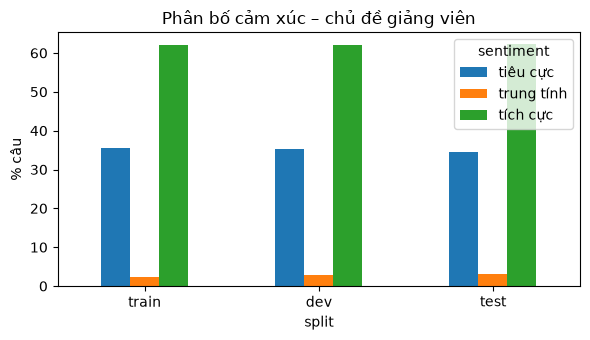

In [4]:
sent_tab = (pd.crosstab(lec.split, lec.sentiment.map(SENT_NAMES))
              .reindex(index=SPLITS, columns=SENT_ORDER, fill_value=0))
display(sent_tab)
sent_pct = (sent_tab.div(sent_tab.sum(axis=1), axis=0) * 100).round(1)
display(sent_pct)

ax = sent_pct.plot(kind="bar", rot=0, figsize=(6, 3.5))
ax.set_ylabel("% câu"); ax.set_title("Phân bố cảm xúc – chủ đề giảng viên")
plt.tight_layout(); plt.show()

### 3.2 Độ dài câu
Dữ liệu đã được tách token sẵn (token cách nhau bằng khoảng trắng, dấu câu tách riêng). Token ở đây xấp xỉ **âm tiết**, không phải từ ghép (ví dụ "giảng viên" = 2 token).

split            dev    test   train
n_tok  count  1151.0  2290.0  8166.0
       mean     13.4    13.7    13.7
       std       9.9     9.1     9.2
       min       2.0     3.0     2.0
       50%      11.0    11.0    11.0
       90%      23.0    25.0    25.0
       95%      30.0    33.0    31.0
       max     161.0    78.0   159.0
n_char count  1151.0  2290.0  8166.0
       mean     55.1    56.7    56.7
       std      42.7    39.3    39.4
       min       4.0     8.0     5.0
       50%      44.0    45.0    46.0
       90%      98.0   106.0   104.0
       95%     125.0   138.0   131.0
       max     718.0   317.0   660.0

,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
tiêu cực,4105.0,16.4,11.9,2.0,8.0,13.0,21.0,161.0
trung tính,292.0,10.2,7.8,2.0,5.0,8.0,12.0,60.0
tích cực,7210.0,12.3,7.0,2.0,8.0,11.0,15.0,95.0


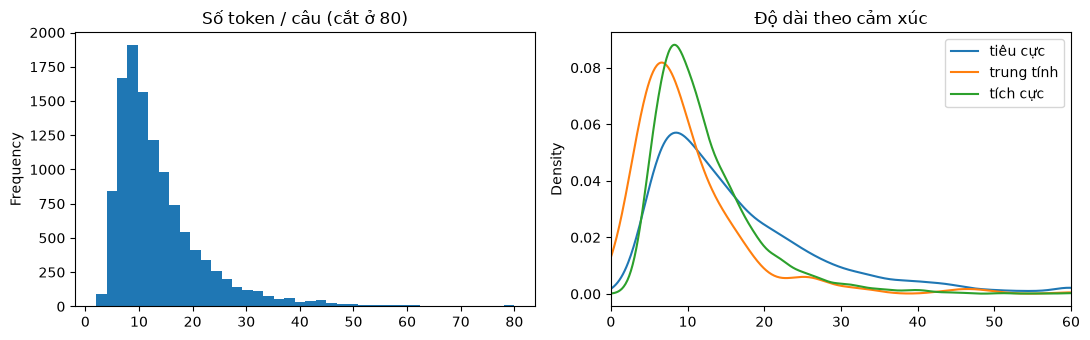

Câu ≤1 token: 0 | câu >60 token: 42


In [5]:
lec["n_tok"] = lec.sent.str.split().str.len()
lec["n_char"] = lec.sent.str.len()

display(lec.groupby("split")[["n_tok", "n_char"]].describe(percentiles=[.5, .9, .95]).round(1).T)
display(lec.groupby(lec.sentiment.map(SENT_NAMES)).n_tok.describe().round(1))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
lec.n_tok.clip(upper=80).plot(kind="hist", bins=40, ax=axs[0])
axs[0].set_title("Số token / câu (cắt ở 80)")
for s, g in lec.groupby("sentiment"):
    g.n_tok.clip(upper=60).plot(kind="kde", ax=axs[1], label=SENT_NAMES[s])
axs[1].set_xlim(0, 60); axs[1].legend(); axs[1].set_title("Độ dài theo cảm xúc")
plt.tight_layout(); plt.show()
print("Câu ≤1 token:", int((lec.n_tok <= 1).sum()), "| câu >60 token:", int((lec.n_tok > 60).sum()))

### 3.3 Tần suất từ và token lạ
Danh sách stopword chỉ dùng để **vẽ biểu đồ**. Cố ý **giữ lại** "không", "rất", "nhưng" vì đề cương lưu ý các từ này làm thay đổi ý nghĩa cảm xúc; không dùng lại danh sách này khi huấn luyện mô hình.

Số token: 139398 | từ vựng (đơn vị tách khoảng trắng): 2243
Token chỉ xuất hiện 1 lần: 852

Token lạ / ký tự đặc biệt / số (top 20):


,token,tần suất
0,2,50
1,3,39
2,colonsmile,32
3,1,31
4,30,26
5,5,26
6,4,22
7,fraction,20
8,colonsmilesmile,16
9,15,14


Gồm stopword          Bỏ stopword         
             từ tần suất          từ tần suất
0          viên     5624        viên     5624
1         giảng     4775       giảng     4775
2          thầy     4224        thầy     4224
3           dạy     4212         dạy     4212
4          sinh     3336        sinh     3336
5          tình     3135        tình     3135
6         nhiệt     2710       nhiệt     2710
7           rất     2471         rất     2471
8           bài     2330         bài     2330
9           học     2164         học     2164
10           và     2120        hiểu     2117
11         hiểu     2117       không     1952
12        không     1952          dễ     1881
13           dễ     1881          cô     1602
14          cho     1734         tâm     1450
15           có     1709         tận     1385
16           cô     1602         tập     1302
17        nhiều     1481         hay     1147
18          tâm     1450        thức      986
19          tận     1385        kiến      981
20          tập     1302         vui      942
21          hay     1147         lớp      940
22          với     1059        thực      828
23         thức      986         tốt      801
24         kiến      981       trong      782
25          của      971         hơn      766
26          vui      942      truyền      752
27          lớp      940         đạt      731
28           em      834        giáo      720
29         thực      828        cách      708

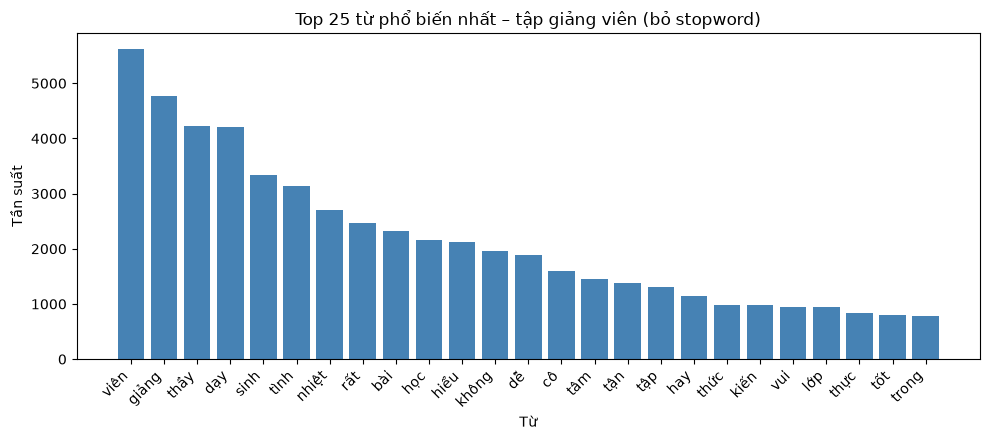

In [8]:
PUNCT = set(list(".,!?;:-()\"'…+/*[]{}=<>@#$%^&") + ["..."])
STOP = set("là và của có các thì được cho một mà để em ở với này đã cũng khi nhiều như còn đó vào ra lại cả nên bị thế".split())

def toks(s):
    return [t for t in s.split() if t not in PUNCT]

cnt_all = collections.Counter(t for s in lec.sent for t in toks(s))
print("Số token:", sum(cnt_all.values()), "| từ vựng (đơn vị tách khoảng trắng):", len(cnt_all))
print("Token chỉ xuất hiện 1 lần:", sum(1 for c in cnt_all.values() if c == 1))

# Token lạ: số, chữ lẫn số, ký tự đặc biệt, token dạng mã (colon..., fraction, wzjwz...)
WEIRD_RE = re.compile(r"^(colon\w*|fraction|wzjwz\w*)$")
def is_weird(tok):
    t = tok.strip(".,!?;:()\"'[]{}+=/*%$-").lower()
    if not t:
        return False
    if WEIRD_RE.match(t) or re.fullmatch(r"\d+([.,]\d+)?", t):
        return True
    if re.search(r"\d", t) and re.search(r"[^\W\d_]", t):   # lẫn chữ và số
        return True
    return bool(re.search(r"[^\w\s]", t))                    # chứa ký tự đặc biệt

weird = collections.Counter(t.lower() for s in lec.sent for t in s.split() if is_weird(t))
print("\nToken lạ / ký tự đặc biệt / số (top 20):")
display(pd.DataFrame(weird.most_common(20), columns=["token", "tần suất"]))

def topn(counter, n=30, stop=False):
    items = [(w, c) for w, c in counter.most_common() if not (stop and w in STOP)]
    return pd.DataFrame(items[:n], columns=["từ", "tần suất"])

display(pd.concat([topn(cnt_all, 30), topn(cnt_all, 30, True)], axis=1, keys=["Gồm stopword", "Bỏ stopword"]))

terms = topn(cnt_all, 25, True)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(terms["từ"], terms["tần suất"], color="steelblue")
ax.set_title("Top 25 từ phổ biến nhất – tập giảng viên (bỏ stopword)")
ax.set_xlabel("Từ"); ax.set_ylabel("Tần suất")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

In [9]:
# Từ nổi bật theo nhãn: log-odds đơn giản (có làm mịn) giữa tiêu cực và tích cực
cn = collections.Counter(t for s in lec[lec.sentiment == 0].sent for t in toks(s))
cp = collections.Counter(t for s in lec[lec.sentiment == 2].sent for t in toks(s))
vocab = [w for w in set(cn) | set(cp) if cn[w] + cp[w] >= 15]
Nn, Np = sum(cn.values()), sum(cp.values())
lo = {w: np.log((cn[w] + 1) / (Nn + len(vocab))) - np.log((cp[w] + 1) / (Np + len(vocab))) for w in vocab}
srt = sorted(lo.items(), key=lambda x: x[1])
display(pd.DataFrame({"nghiêng về TÍCH CỰC": [w for w, _ in srt[:20]],
                      "nghiêng về TIÊU CỰC": [w for w, _ in srt[::-1][:20]]}))

,nghiêng về TÍCH CỰC,nghiêng về TIÊU CỰC
0,hòa,trễ
1,vui,mơ
2,hước,sài
3,gũi,hơi
4,nghề,hưởng
5,thương,muộn
6,huyết,rồi
7,vời,hôm
8,nhiệt,hạn
9,vẻ,3


### 3.4 Câu có phủ định, từ chỉ mức độ, từ nối "nhưng"
Các danh sách từ dưới đây là bản khởi đầu; cần rà lại sau khi đọc mẫu (viết tắt, sai chính tả).

In [10]:
INTENSIFIERS = ["rất", "hơi", "quá", "khá", "cực kỳ", "siêu", "lắm"]
NEG_WORDS = ["không", "chưa", "chẳng", "chả", "ko", "hok", "hông", "đâu có"]
NEG_EXCLUDE = ["không những", "không gian", "không khí"]    # cụm chứa "không" nhưng không phải phủ định
CONTRAST = ["nhưng"]
CONTRAST_WIDE = ["nhưng", "tuy nhiên", "tuy", "mặc dù", "dù", "song"]

def pad(s):
    return " " + (s or "").lower() + " "

def has_any(s, words):
    s = pad(s)
    return any(f" {w} " in s for w in words)

def has_negation(s):
    s = pad(s)
    for p in NEG_EXCLUDE:
        s = s.replace(f" {p} ", " ")
    return any(f" {w} " in s for w in NEG_WORDS)

lec["has_nhung"] = lec.sent.apply(lambda s: has_any(s, CONTRAST))
lec["has_contrast_wide"] = lec.sent.apply(lambda s: has_any(s, CONTRAST_WIDE))
lec["has_neg"] = lec.sent.apply(has_negation)
lec["has_intensity"] = lec.sent.apply(lambda s: has_any(s, INTENSIFIERS))
lec["has_either"] = lec.has_nhung | lec.has_neg

FLAGS = ["has_nhung", "has_neg", "has_either", "has_contrast_wide", "has_intensity"]
print("Tỉ lệ (%) câu có từng đặc điểm, theo tập:")
display((lec.groupby("split")[FLAGS].mean().reindex(SPLITS) * 100).round(1))
print("Tỉ lệ (%) theo cảm xúc:")
display((lec.groupby(lec.sentiment.map(SENT_NAMES))[FLAGS].mean().reindex(SENT_ORDER) * 100).round(1))

for col in ["has_nhung", "has_neg", "has_intensity"]:
    print(f"Phân bố cảm xúc của các câu {col}:")
    display(lec[lec[col]].sentiment.map(SENT_NAMES).value_counts(normalize=True).mul(100).round(1).to_frame("%"))

for col, title in [("has_nhung", "'nhưng'"), ("has_neg", "phủ định"), ("has_intensity", "từ nhấn mạnh")]:
    sub = lec[lec[col]]
    print(f"Ví dụ câu có {title}:")
    display(sub.sample(min(8, len(sub)), random_state=SEED)[["sent", "sentiment"]])

Tỉ lệ (%) câu có từng đặc điểm, theo tập:


,has_nhung,has_neg,has_either,has_contrast_wide,has_intensity
split,,,,,
train,3.3,17.3,18.9,4.3,29.6
dev,3.3,15.2,16.8,3.7,28.7
test,3.7,18.1,20.0,4.3,31.1


Tỉ lệ (%) theo cảm xúc:


,has_nhung,has_neg,has_either,has_contrast_wide,has_intensity
sentiment,,,,,
tiêu cực,7.0,41.3,44.0,8.5,30.0
trung tính,6.2,17.8,21.2,6.8,10.6
tích cực,1.2,3.5,4.5,1.7,30.4


Phân bố cảm xúc của các câu has_nhung:


...

,sent,sentiment
3725,"thầy hay kéo giờ nhưng dạy tận tình , cho ví dụ và bài tập dễ hiểu .",2
15353,"thầy dạy hơi nhiều , nhưng làm bài tập tốt và sát với đề .",2
10409,thầy nghiêm khắc nhưng rất nhiệt tình !,2
2619,đọc slide có thể hiểu nội dung nhưng sau khi thầy giảng lại thì không hiểu tí gì hết .,0
15994,"giờ học là 7h30 thì 8h thầy vào lớp , hết tiết là 9h45 nhưng lại học tới 10h15 .",0
9359,cô cho nghỉ nhiều quá ( mặc dù đã có bù ) nhưng nên đảm bảo đúng lịch để sinh viên sắp xếp thời gian bởi vì sinh viê...,0
2194,"giảng viên tận tâm , nhiệt tình , còn trẻ nhưng kiến thức rất tốt .",2
9536,"theo thời khóa biểu là mỗi buổi 4 tiết , nhưng thầy chưa bao giờ dạy hơn 3 tiết fraction buổi , thầy hay kể chuyện k...",0


Ví dụ câu có phủ định:


,sent,sentiment
1977,"phương pháp giảng dạy chưa được tốt , cần phải cụ thể hơn để cho sinh viên dễ hiểu hơn nữa .",0
2719,"nhiều lúc báo cáo tiến độ đồ án , khi không hài lòng , giảng viên đã nói thẳng với sinh viên là rớt môn dù cho còn 1...",0
2284,"không gian học thoải mái , giảng viên không tạo áp lực cho sinh viên .",2
4301,đôi lúc giảng viên nói quá nhỏ không thể nghe thấy rõ .,0
10349,"tuy nhiên cách truyền đạt của thầy vẫn chưa dễ hiểu lắm , nên nói ít lý thuyết hơn .",0
10322,"phương pháp giảng dạy và cách tiếp cận với sinh viên rất tư nhiên , không gò bó .",2
3188,"cho nhiều bài tập nhưng không giải , sinh viên chỉ biết làm mà không biết mình làm đúng hay không .",0
16039,"thầy day dễ hiểu , dễ nắm bắt được kiến thức , không dạy lan man .",2


Ví dụ câu có từ nhấn mạnh:


,sent,sentiment
8237,đôi lúc tính tình thầy hơi khó nhai colonbigsmile .,0
290,"nhưng học mới thấy kiến thức thầy dạy rất hay , bám sát thực tế , thầy dạy rất nhiệt tình , vui vẻ , khác với mọi ng...",2
885,giáo viên rất tận tâm nhiệt tình .,2
13053,cô dạy rất tốt và nhiệt tình .,2
9396,dạy rất kỹ .,2
11586,"giảng viên thường cho một số bài tập nâng cao , hơi quá sức đối với tụi em .",0
10039,truyền đạt bài giảng rất tốt .,2
11415,cô cho bài tập hơi nhiều ( nhưng mà không sao colonsmilesmile ) .,1


### 3.5 Câu trùng và nhãn mâu thuẫn
Kiểm tra (a) trùng trong cùng tập, (b) trùng giữa các tập (nguy cơ rò rỉ dữ liệu), (c) cùng câu nhưng khác nhãn cảm xúc.

In [11]:
for sp, g in all_df.groupby("split", sort=False):
    n_uni = g.key.nunique()
    print(f"{sp}: {len(g)} câu | {n_uni} duy nhất | {len(g) - n_uni} dòng trùng ({(1 - n_uni / len(g)) * 100:.2f}%)")

sets = {sp: set(g.key) for sp, g in all_df.groupby("split")}
for a, b in [("train", "dev"), ("train", "test"), ("dev", "test")]:
    print(f"Câu trùng giữa {a} và {b}: {len(sets[a] & sets[b])}")

conf = all_df.groupby("key").sentiment.nunique()
conf_keys = set(conf[conf > 1].index)
print("Câu giống hệt nhau nhưng khác nhãn cảm xúc:", len(conf_keys))
display(all_df[all_df.key.isin(conf_keys)].sort_values("key")[["split", "sent", "sentiment", "topic"]].head(20))

dup_key = all_df[all_df.duplicated("key", keep=False)]
print("Số dòng trùng theo key trên toàn bộ dữ liệu:", len(dup_key))
display(dup_key.sort_values("key")[["split", "sent", "sentiment", "topic"]].head(20))

train: 11426 câu | 11425 duy nhất | 1 dòng trùng (0.01%)
dev: 1583 câu | 1583 duy nhất | 0 dòng trùng (0.00%)
test: 3166 câu | 3166 duy nhất | 0 dòng trùng (0.00%)
Câu trùng giữa train và dev: 0
Câu trùng giữa train và test: 0
Câu trùng giữa dev và test: 0
Câu giống hệt nhau nhưng khác nhãn cảm xúc: 1


,split,sent,sentiment,topic
11293,train,"thầy dạy hay , tuy nhiên còn nhiều chỗ chưa thật sự giải đáp hoàn toàn cho sinh viên vì chưa đủ thời gian .",2,0
11417,train,"thầy dạy hay , tuy nhiên còn nhiều chỗ chưa thật sự giải đáp hoàn toàn cho sinh viên vì chưa đủ thời gian .",0,0


Số dòng trùng theo key trên toàn bộ dữ liệu: 2


,split,sent,sentiment,topic
11293,train,"thầy dạy hay , tuy nhiên còn nhiều chỗ chưa thật sự giải đáp hoàn toàn cho sinh viên vì chưa đủ thời gian .",2,0
11417,train,"thầy dạy hay , tuy nhiên còn nhiều chỗ chưa thật sự giải đáp hoàn toàn cho sinh viên vì chưa đủ thời gian .",0,0


## 4. Rút mẫu để gán nhãn ABSA thử
Mẫu 200 câu giảng viên từ **train**, với các ràng buộc:
- bỏ câu ≤ 2 token, bỏ câu trùng trong train;
- **bỏ câu trùng với dev/test** (để mẫu không gây rò rỉ giữa các tập);
- bỏ câu có nhãn cảm xúc mâu thuẫn ở bản trùng;
- cân bằng nhãn cảm xúc gốc nếu `BALANCE_SENTIMENT = True` (lấy tối đa N/3 mỗi lớp, phần thiếu bù ngẫu nhiên).

In [12]:
N_SAMPLE = 200
BALANCE_SENTIMENT = True
MIN_TOKENS = 3

other_keys = set(all_df[all_df.split != "train"].key)
pool = lec[(lec.split == "train") & (lec.n_tok >= MIN_TOKENS)].drop_duplicates("key")
pool = pool[~pool.key.isin(other_keys) & ~pool.key.isin(conf_keys)]
print(f"Kích thước pool hợp lệ: {len(pool)}")

def balanced_sample(df, n, col, seed):
    per = n // df[col].nunique()
    parts = [g.sample(min(len(g), per), random_state=seed) for _, g in df.groupby(col)]
    chosen = pd.concat(parts)
    short = n - len(chosen)
    if short > 0:
        rest = df.drop(chosen.index)
        chosen = pd.concat([chosen, rest.sample(min(short, len(rest)), random_state=seed)])
    return chosen.sample(frac=1, random_state=seed)

n = min(N_SAMPLE, len(pool))
picked = balanced_sample(pool, n, "sentiment", SEED) if BALANCE_SENTIMENT else pool.sample(n, random_state=SEED)
sample = picked.reset_index(drop=True)
sample.insert(0, "id", range(1, n + 1))

# Template: mỗi khía cạnh một cột. Để trống = không đề cập; 0/1/2 = tiêu cực/trung tính/tích cực
template = sample[["id", "split", "idx", "sent"]].copy()
template["overall_sentiment"] = ""
for code in ASPECT_CODES:
    template[code] = ""
template["note"] = ""

for annotator in (1, 2):
    out = template.copy()
    out.insert(0, "annotator_id", annotator)
    out.to_csv(OUT_DIR / f"annotation_sample_absa_annotator{annotator}.csv", index=False, encoding="utf-8-sig")

# Nhãn gốc của UIT-VSFC – chỉ dùng đối chiếu sau khi gán xong
sample[["id", "split", "idx", "sent", "sentiment", "topic"]].to_csv(
    OUT_DIR / "annotation_sample_original_labels.csv", index=False, encoding="utf-8-sig")

print(f"Đã lưu {n} câu vào {OUT_DIR}")
cmp = (sample.sentiment.map(SENT_NAMES).value_counts(normalize=True).mul(100).round(1).reindex(SENT_ORDER).to_frame("mẫu")
       .join(lec[lec.split == "train"].sentiment.map(SENT_NAMES).value_counts(normalize=True).mul(100).round(1).to_frame("train giảng viên")))
display(cmp)
print("Tỉ lệ câu trong mẫu có 'nhưng' / phủ định (%):",
      round(sample.has_nhung.mean() * 100, 1), "/", round(sample.has_neg.mean() * 100, 1))
sample[["id", "sent"]].head(10)

Kích thước pool hợp lệ: 8159
Đã lưu 200 câu vào z:\ML\fle\output


,mẫu,train giảng viên
sentiment,,
tiêu cực,33.5,35.6
trung tính,33.0,2.3
tích cực,33.5,62.1


Tỉ lệ câu trong mẫu có 'nhưng' / phủ định (%): 3.5 / 22.5


,id,sent
0,1,do chỉ mới được học thầy nhiệm trong 2 tuần cuối nên em không có đủ thời gian tiếp súc để đưa ra đánh giá cho khảo s...
1,2,"thầy biết rõ sự chênh lệch về trình độ giữa khóa 9 và khóa 10 trong lớp nên đưa ra cách đánh giá hợp lý , thầy nói r..."
2,3,thực sự thầy sử dụng giời lên lớp chưa hiệu quả .
3,4,"thầy tận tâm với sinh viên , hay trò chuyện cùng sinh viên ."
4,5,có một lần cúp điện cô không dùng slide để giảng bài em thấy dễ hiểu hơn nhiều .
5,6,cơ mà em nghĩ là thầy phải hơn cả tuổi ba em .
6,7,"giảng viên cho sinh viên thực hiện một dự án thực tế ngoài nội dung môn học , với mục tiêu áp dụng quy trình scrum ."
7,8,giảng viên dễ chịu vui tính .
8,9,"thầy dạy nhiệt tình , gần gũi , vui vẻ trong buổi học ."
9,10,"thầy dạy thực hành không hiệu quả , hầu như các buổi thực hành , thầy cho bài làm theo tuần , sinh viên tự tìm hiểu ."
